# Water vapour and above-water radiometry, 900–1000 nm

This tutorial uses the Python package `sosabs` to build a **NetCDF look-up
table (LUT)** with SOS-ABS and to quantify the impact of the water vapour
absorption band centred at 940 nm on the radiation field **just above the
sea surface**:

* the downward irradiance $E_d(0^+)$ (direct and diffuse),
* the sky radiance $L_{sky}$ seen by an upward-looking radiometer,
* the total radiance $L_t(0^+)$ seen by a downward-looking radiometer
  (sky and sun glint reflected by the rough sea surface),
* the ratio $\rho = L_t / L_{sky}$, used to remove the surface-reflected
  sky radiance in above-water radiometry.

The usual viewing geometry of above-water measurements is used
(Mobley, 1999): viewing zenith angle 40° and relative azimuth 135° from the Sun.

```{note}
The CKD tables of SOS-ABS stop just below 10 000 cm⁻¹: the last wavelength of the
LUT is 998 nm (a run at 1000 nm stops with "The summation of AIK coefs is not 1").
```

```{note}
SOS-ABS has no water body: the sea is a black Fresnel interface, so
$L_t(0^+)$ is the surface-reflected radiance only. Between 900 and 1000 nm the
water-leaving radiance is very small for most waters, so this is a fair
approximation of the signal measured over the sea.
```

```{note}
Running this notebook requires the compiled code (executable and/or f2py
module, see {doc}`../installation`) and the CKD data of `fic/`. The figures shown in
the documentation were computed beforehand.
```

## Setup

In [1]:
import os
import sys
import time
import warnings

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm

# Root of the SOS-ABS repository (this notebook is in docs/source/tutorials)
ROOT = os.environ.setdefault("SOS_ABS_ROOT", os.path.abspath("../../.."))
sys.path.insert(0, os.path.join(ROOT, "python"))   # if sosabs is not pip-installed

import sosabs

warnings.simplefilter("ignore", FutureWarning)   # xarray / pandas deprecations
warnings.filterwarnings("ignore", message="Auto-removal of grids")  # matplotlib 3.5

print("SOS-ABS root :", ROOT)
print("backend      :", sosabs.available_backend())   # 'f2py' (in memory) or 'exe'

SOS-ABS root : /home/harmel/Dropbox/Dropbox/work/git/vrtc/RadiativeTransferCode-SOS
backend      : f2py


In [2]:
# Plot style: thin lines, recessive grid and axes
INK, INK2, GRID = "#1f1f1e", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "legend.frameon": False,
})
# water vapour amounts: one hue, light -> dark (ordered quantity)
H2O_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
# two categories (e.g. CKD modes)
CAT = ["#2a78d6", "#eb6834"]
# sequential colormap for the polar diagrams
SEQ = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

## Common configuration

The parameters are given with the SOS-ABS command-line keywords (the Python
names of {doc}`../parameters` are accepted too). Gaseous absorption uses the
CKD coefficients at 5 cm⁻¹ resolution with the *fine* coupling of absorption and
scattering (`-SOS.AbsModeCKD 1`: one radiance computation per CKD term).

In [3]:
SZA = 40.0       # solar zenith angle (deg)
VZA = 40.0       # viewing angle of the radiometers (deg): from nadir for Lt, from zenith for Lsky
AZI = 135.0      # relative azimuth from the Sun (deg)

config = {
    # angles: 24 Gauss angles, polar diagram every 5 deg of azimuth
    "-ANG.Thetas": SZA, "-ANG.Rad.NbGauss": 24, "-SOS.View.Dphi": 5,
    # radiation field just above the surface (z = 0 km)
    "-SOS.OutputAlt": 0.0,
    # atmosphere: mid-latitude summer gas profile (H2O scaled by -AP.H2O)
    "-AP.Psurf": 1013.0, "-AP.HR": 8.0,
    "-AP.AbsProfile.Type": 2, "-AP.SpectralResol": 5.0, "-SOS.AbsModeCKD": 1,
    # aerosols: WMO maritime, exponential profile (scale height 2 km), AOT(550) = 0.1
    "-AP.AerProfile.Type": 1, "-AP.AerHS.HA": 2.0,
    "-AER.Model": 1, "-AER.WMO.Model": 2, "-AER.Waref": 0.55, "-AER.AOTref": 0.1,
    # rough sea surface (Cox & Munk), wind 5 m/s, no lambertian component
    "-SURF.Type": 1, "-SURF.Ind": 1.33, "-SURF.Glitter.Wind": 5.0, "-SURF.Alb": 0.0,
}

## Spectral sampling and CKD intervals

The radiances are computed every **0.5 nm**. SOS-ABS takes the absorption of the
CKD interval containing the wavelength, so the resolution of the CKD tables must
match the sampling: the 10 cm⁻¹ intervals are about 1 nm wide between 900 and
1000 nm (two consecutive 0.5 nm samples would share the same absorption),
whereas the 5 cm⁻¹ intervals are 0.40 to 0.50 nm wide.

The NetCDF version of the CKD tables (`sosabs.ckd`, see {doc}`../ckd`) makes this
check, and a first look at the band, immediate:

In [4]:
ckd = sosabs.ckd.open_ckd(5, create=True)      # fic/COEFF_CKD/ckd_5cmm1.nc
band = ckd.sel(wavenumber=slice(1e4 / 1.000, 1e4 / 0.900))   # 900-1000 nm

wl = np.round(np.arange(0.900, 0.9981, 0.0005), 4)         # 0.5 nm step (um)
wmin = ckd.wavenumber_min.values
interval = np.searchsorted(wmin, 1e4 / wl, side="right") - 1   # CKD interval of each wavelength
width = 1e3 * (1e4 / band.wavenumber_min - 1e4 / band.wavenumber_max)

print("LUT wavelengths         : %d (%.1f-%.1f nm, step 0.5 nm)" % (wl.size, wl[0] * 1e3, wl[-1] * 1e3))
print("5 cm-1 intervals hit    : %d distinct (out of %d in 900-1000 nm)" % (np.unique(interval).size, band.wavenumber.size))
print("width of the intervals  : %.2f to %.2f nm" % (width.min(), width.max()))
print("H2O terms per interval  : max %d, mean %.1f" % (band.n_term.sel(gas="H2O").max(), band.n_term.sel(gas="H2O").mean()))

LUT wavelengths         : 197 (900.0-998.0 nm, step 0.5 nm)
5 cm-1 intervals hit    : 197 distinct (out of 222 in 900-1000 nm)
width of the intervals  : 0.41 to 0.50 nm
H2O terms per interval  : max 5, mean 4.8


Number of terms of the H₂O CKD expansion (each term is one radiative transfer
computation with the fine coupling `-SOS.AbsModeCKD 1`) and transmission of a
vertical H₂O column, approximated by a homogeneous layer (800 hPa, 280 K,
mean mole fraction of the column) with `sosabs.ckd.transmittance`:

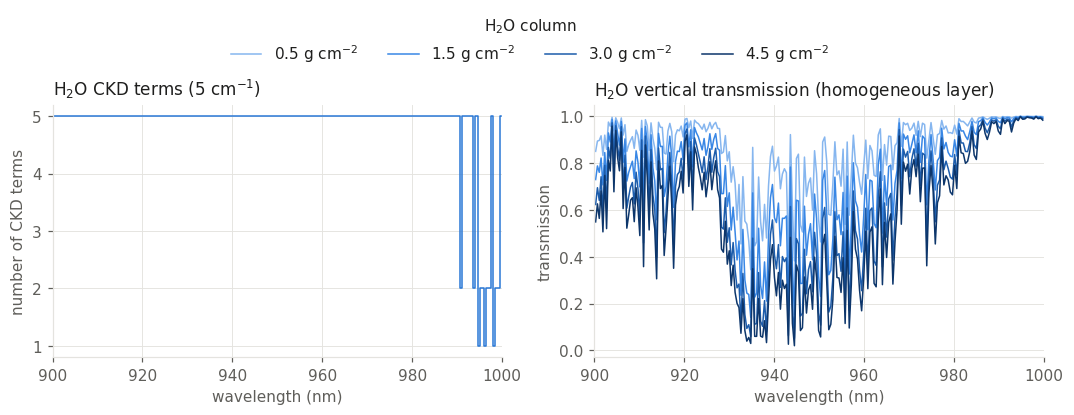

In [5]:
NA, M_H2O, N_AIR = 6.022e23, 18.015, 2.15e25   # Avogadro, g/mol, air column (molecules cm-2)
h2o = [0.5, 1.5, 3.0, 4.5]                        # water vapour column (g cm-2)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
nt = band.n_term.sel(gas="H2O")
axs[0].step(band.wavelength * 1e3, nt, where="mid", color=CAT[0], linewidth=1.0)
axs[0].set_ylabel("number of CKD terms"); axs[0].set_title("H$_2$O CKD terms (5 cm$^{-1}$)", loc="left")
for c, h in zip(H2O_COLORS, h2o):
    u = h / M_H2O * NA                            # molecules cm-2
    t = sosabs.ckd.transmittance(band, "H2O", u, pressure=800., temperature=280.,
                                 h2o_fraction=u / N_AIR)
    axs[1].plot(band.wavelength * 1e3, t, color=c, linewidth=1.0, label="%.1f g cm$^{-2}$" % h)
axs[1].set_ylabel("transmission"); axs[1].set_title("H$_2$O vertical transmission (homogeneous layer)", loc="left")
for ax in axs:
    ax.set_xlabel("wavelength (nm)"); ax.set_xlim(900, 1000)
fig.legend(*axs[1].get_legend_handles_labels(), title="H$_2$O column", ncol=4,
           loc="upper center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.86))

## One simulation at 940 nm

`sosabs.run` returns an `xarray.Dataset`. The Stokes parameters are
normalised radiances $\pi L / E_0$ ($E_0$: extraterrestrial solar irradiance
normal to the beam), for the upward (`*_up`) and downward (`*_down`) fields,
versus the viewing zenith angle `vza` and the relative azimuth `azi`.
The fluxes are normalised to the TOA solar flux $E_0 \cos\theta_s$.

In [6]:
t0 = time.time()
ds = sosabs.run({**config, "-SOS_Main.Wa": 0.94, "-AP.H2O": 2.0})
print("computing time: %.1f s" % (time.time() - t0))
ds

computing time: 7.7 s


<xarray.Dataset>
Dimensions:          (vza: 25, azi: 73)
Coordinates:
  * vza              (vza) float64 2.841 6.521 10.22 13.93 ... 80.72 84.43 88.14
  * azi              (azi) float64 0.0 5.0 10.0 15.0 ... 345.0 350.0 355.0 360.0
    gauss_weight     (vza) float64 0.003153 0.007328 0.01148 ... 0.06447 0.06474
    user_angle       (vza) int8 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
Data variables: (12/13)
    I_up             (vza, azi) float64 0.002178 0.002173 ... 0.04923 0.05244
    Q_up             (vza, azi) float64 -0.0003869 -0.0003805 ... -0.02028
    U_up             (vza, azi) float64 0.0 6.275e-05 ... -0.001008 0.0
    I_down           (vza, azi) float64 0.02001 0.02 0.01996 ... 0.03195 0.03227
    Q_down           (vza, azi) float64 0.0001087 0.0001064 ... -0.0007595
    U_down           (vza, azi) float64 0.0 2.051e-05 ... 2.088e-05 0.0
    ...               ...
    scat_angle_down  (vza, azi) float64 37.16 37.17 37.2 ... 48.89 48.33 48.14
    flux_dir_down    float64 0.3846
    flux_diff_down   float64 0.04223
    flux_tot_down    float64 0.4269
    flux_diff_up     float64 0.01116
    coef_tronca      float64 0.4234
Attributes: (12/33)
    title:                   SOS-ABS radiative transfer simulation
    source:                  SOS-ABS (Successive Orders of Scattering coupled...
    references:              Lenoble et al. (2007), JQSRT 107(3), doi:10.1016...
    sosabs_python_version:   0.1.0
    sos_backend:             f2py
    normalisation:           Stokes parameters normalised to the extraterrest...
    ...                      ...
    sos_SOS_OutputAlt:       0.0
    sos_SOS_IGmax:           100
    sos_SOS_Ipolar:          1
    sos_SOS_View:            2
    sos_SOS_View_Dphi:       5
    sos_SOS_AbsModeCKD:      1

The relative azimuth follows the SOS-ABS convention (attribute
`azimuth_convention`): **0° when the radiometer looks towards the Sun's
azimuth**. The sun glint then appears at `azi` = 0° in the upward field
and the solar aureole at `azi` = 0° in the downward field, both at
`vza` ≈ θs.

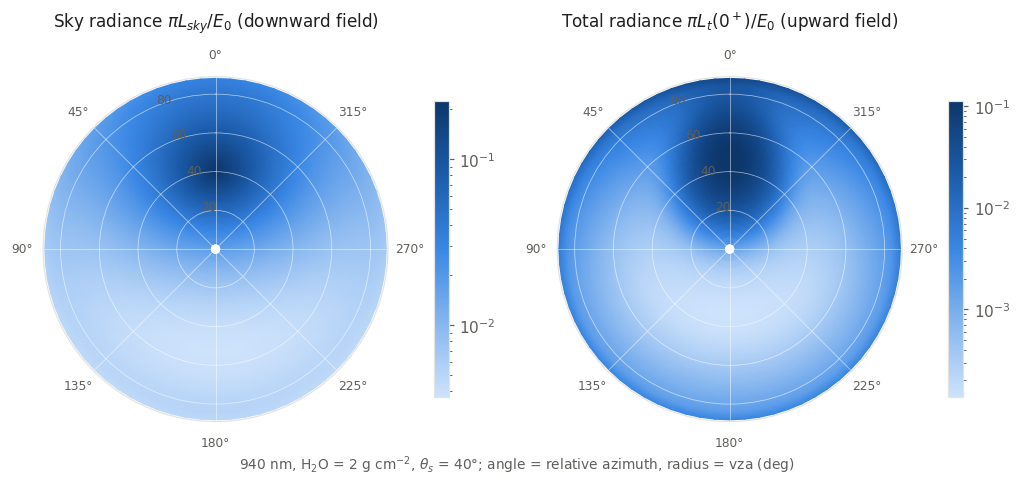

In [7]:
def polar(ax, da, title, vmin=None, vmax=None):
    # azimuth 0..360 deg on the angle axis, vza on the radius
    th = np.deg2rad(da.azi.values)
    ax.grid(False)
    m = ax.pcolormesh(th, da.vza.values, da.values, shading="gouraud", cmap=SEQ,
                      norm=LogNorm(vmin=vmin or float(da.min()), vmax=vmax or float(da.max())))
    ax.set_theta_zero_location("N")
    ax.set_rlim(0, 89)
    ax.set_rticks([20, 40, 60, 80])
    ax.tick_params(labelsize=8, colors=INK2)
    ax.grid(color="white", linewidth=0.5, alpha=0.6)
    ax.set_title(title, pad=14)
    return m

fig, axs = plt.subplots(1, 2, figsize=(9.5, 4.4), subplot_kw=dict(projection="polar"))
m = polar(axs[0], ds.I_down, "Sky radiance $\\pi L_{sky}/E_0$ (downward field)")
fig.colorbar(m, ax=axs[0], shrink=0.75, pad=0.1)
m = polar(axs[1], ds.I_up, "Total radiance $\\pi L_t(0^+)/E_0$ (upward field)",
          vmax=float(ds.I_up.quantile(0.995)))
fig.colorbar(m, ax=axs[1], shrink=0.75, pad=0.1)
fig.suptitle("940 nm, H$_2$O = 2 g cm$^{-2}$, $\\theta_s$ = 40°; angle = relative azimuth, radius = vza (deg)",
             fontsize=9, color=INK2, y=0.02)
plt.tight_layout()

## Fast generation of the LUT

`sosabs.build_lut` runs SOS-ABS for every combination of the `grid` values,
in parallel, and gathers the results in one dataset written to NetCDF with:

* one dimension per grid parameter (`wl`, `h2o`) plus `vza` and `azi`,
* units, long names and SOS-ABS keyword of every dimension,
* all the fixed parameters, the code version (with its git commit), the
  normalisation and the azimuth convention as global attributes.

What makes it fast:

1. the Fourier series of the radiance field is recombined for **all the
   azimuths in one reading** of the SOS result file (`SOS_TRPHI_MULTI`),
2. the f2py backend keeps the results in memory (no ASCII file to write and
   parse) in double precision,
3. the runs are parallel; each worker keeps its own cache of Mie and
   surface-matrix files, so they are computed once per worker and never
   written by two runs at the same time.

In [8]:
# wl (0.5 nm step) and h2o are defined above

t0 = time.time()
lut = sosabs.build_lut(grid={"-SOS_Main.Wa": wl, "-AP.H2O": h2o},
                       fixed=config, outfile="lut_h2o_900_1000nm.nc",
                       verbose=False)
print("%d runs in %.0f s" % (lut.wl.size * lut.h2o.size, time.time() - t0))

788 runs in 190 s


The LUT is a standard NetCDF file and can be re-opened with any NetCDF tool:

In [9]:
lut = xr.open_dataset("lut_h2o_900_1000nm.nc")
lut

<xarray.Dataset>
Dimensions:          (wl: 197, h2o: 4, vza: 25, azi: 73)
Coordinates:
  * wl               (wl) float64 0.9 0.9005 0.901 0.9015 ... 0.997 0.9975 0.998
  * h2o              (h2o) float64 0.5 1.5 3.0 4.5
  * vza              (vza) float64 2.841 6.521 10.22 13.93 ... 80.72 84.43 88.14
  * azi              (azi) float64 0.0 5.0 10.0 15.0 ... 345.0 350.0 355.0 360.0
    gauss_weight     (vza) float64 ...
    user_angle       (vza) int8 ...
Data variables: (12/13)
    I_up             (wl, h2o, vza, azi) float32 ...
    Q_up             (wl, h2o, vza, azi) float32 ...
    U_up             (wl, h2o, vza, azi) float32 ...
    I_down           (wl, h2o, vza, azi) float32 ...
    Q_down           (wl, h2o, vza, azi) float32 ...
    U_down           (wl, h2o, vza, azi) float32 ...
    ...               ...
    scat_angle_down  (wl, h2o, vza, azi) float32 ...
    flux_dir_down    (wl, h2o) float64 ...
    flux_diff_down   (wl, h2o) float64 ...
    flux_tot_down    (wl, h2o) float64 ...
    flux_diff_up     (wl, h2o) float64 ...
    coef_tronca      (wl, h2o) float64 ...
Attributes: (12/38)
    title:                   SOS-ABS look-up table
    source:                  SOS-ABS (Successive Orders of Scattering coupled...
    references:              Lenoble et al. (2007), JQSRT 107(3), doi:10.1016...
    sosabs_python_version:   0.1.0
    sos_backend:             f2py
    normalisation:           Stokes parameters normalised to the extraterrest...
    ...                      ...
    date_created:            2026-11-10T07:54:06+00:00
    history:                 2026-11-10 07:54:06 UTC: created by sosabs.build...
    lut_dimensions:          wl h2o
    lut_keywords:            -SOS_Main.Wa -AP.H2O
    sos_code_version:        SOS-ABS version 5.1 (git c22446d-dirty)
    n_failed_runs:           0

In [10]:
for key in ["title", "lut_dimensions", "lut_keywords", "sos_code_version", "history",
            "sos_AP_AbsProfile_Type", "sos_SOS_AbsModeCKD", "sos_AER_AOTref", "sos_SURF_Glitter_Wind"]:
    print("%-24s %s" % (key, lut.attrs[key]))
print()
print(lut.attrs["azimuth_convention"])

title                    SOS-ABS look-up table
lut_dimensions           wl h2o
lut_keywords             -SOS_Main.Wa -AP.H2O
sos_code_version         SOS-ABS version 5.1 (git c22446d-dirty)
history                  2026-11-10 07:54:06 UTC: created by sosabs.build_lut (788 runs, 188 s)
sos_AP_AbsProfile_Type   2
sos_SOS_AbsModeCKD       1
sos_AER_AOTref           0.1
sos_SURF_Glitter_Wind    5.0

Relative azimuth between the viewing direction (line of sight) and the solar azimuth: 0 deg <-> sensor and Sun in opposite half-planes (forward scattering, sun glint for the upward field, solar aureole for the downward field); 180 deg <-> sensor and Sun in the same half-plane (backscattering).


## Downward irradiance

The total downward irradiance just above the surface is
$E_d(0^+) = E_0 \cos\theta_s \, T_{tot}$, with $T_{tot}$ = `flux_tot_down`.
The diffuse fraction is `flux_diff_down / flux_tot_down`.

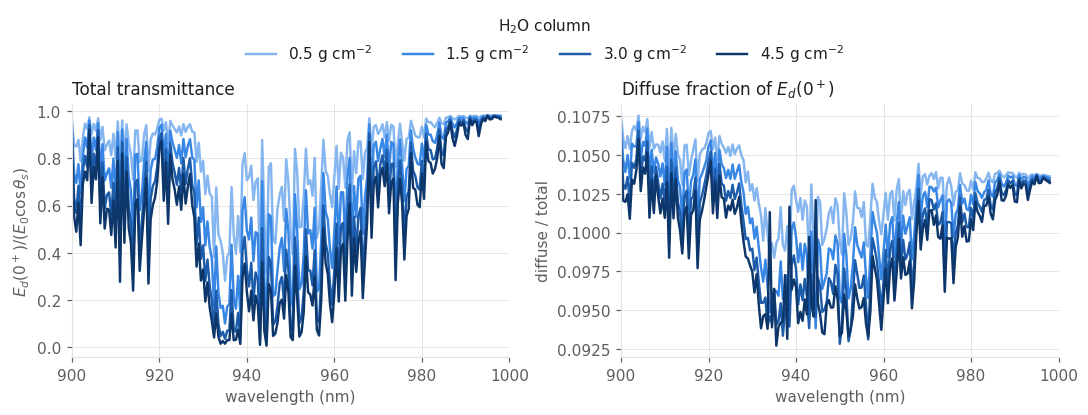

In [11]:
def by_h2o(ax, da, ylabel, title):
    for c, h in zip(H2O_COLORS, da.h2o.values):
        ax.plot(da.wl * 1e3, da.sel(h2o=h), color=c, label="%.1f g cm$^{-2}$" % h)
    ax.set_xlabel("wavelength (nm)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    ax.set_xlim(900, 1000)

def h2o_legend(fig, ax):
    # one legend above the panels, outside the data
    fig.legend(*ax.get_legend_handles_labels(), title="H$_2$O column", ncol=4,
               loc="upper center", bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.86))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
by_h2o(axs[0], lut.flux_tot_down, "$E_d(0^+) / (E_0 \\cos\\theta_s)$", "Total transmittance")
by_h2o(axs[1], lut.flux_diff_down / lut.flux_tot_down, "diffuse / total", "Diffuse fraction of $E_d(0^+)$")
h2o_legend(fig, axs[0])

The fine structure of the spectra is the line structure of the band, seen through
the 5 cm⁻¹ CKD intervals sampled every 0.5 nm (each wavelength falls in its own
interval, see above). The diffuse fraction *decreases* with
water vapour: the diffuse light travels longer paths in the moist lower layers and
is more absorbed than the direct beam.

## Sky radiance, total radiance and their ratio

The LUT is interpolated at the viewing angle of the radiometers
(`vza` = 40°, between two Gauss angles) and taken at `azi` = 135°.

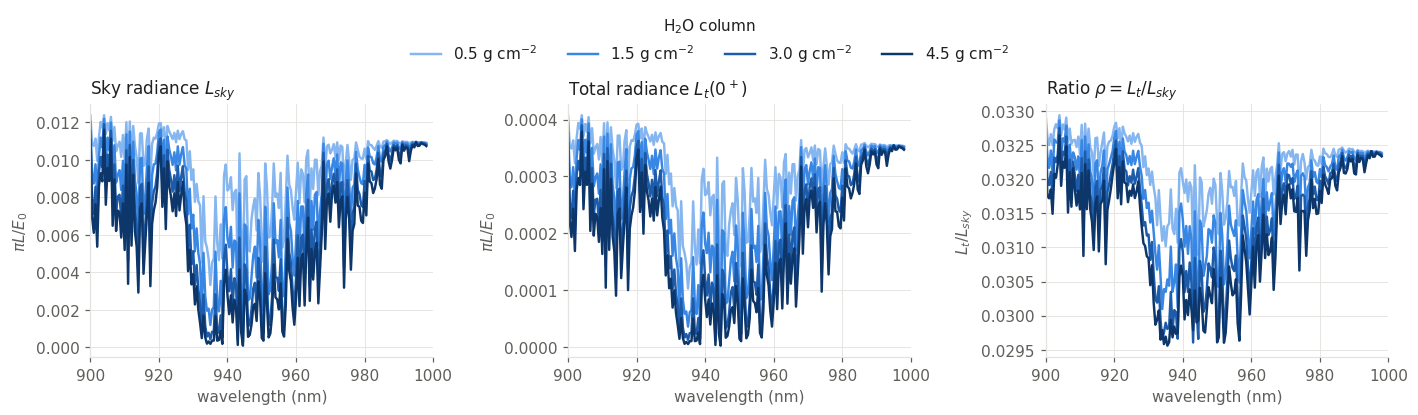

In [12]:
geo = lut.interp(vza=VZA).sel(azi=AZI)
rho = geo.I_up / geo.I_down

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
by_h2o(axs[0], geo.I_down, "$\\pi L / E_0$", "Sky radiance $L_{sky}$")
by_h2o(axs[1], geo.I_up, "$\\pi L / E_0$", "Total radiance $L_t(0^+)$")
by_h2o(axs[2], rho, "$L_t / L_{sky}$", "Ratio $\\rho = L_t / L_{sky}$")
h2o_legend(fig, axs[0])

In the band, both radiances drop strongly with water vapour, but their ratio
$\rho$ changes much less: the sky radiance and the reflected sky radiance
are attenuated along similar paths. The residual variation of $\rho$
comes from the change of the angular distribution of the sky radiance
(longer, more absorbed paths near the horizon) and from the direct sun glint.

Relative change between 0.5 and 4.5 g cm⁻² at the band centre (940 nm, i.e. one
5 cm⁻¹ CKD interval: values at a single wavelength depend on the CKD resolution):

In [13]:
w = 0.940
lo, hi = dict(wl=w, h2o=0.5), dict(wl=w, h2o=4.5)
for name, da in [("Ed(0+)", lut.flux_tot_down), ("Lsky", geo.I_down),
                 ("Lt(0+)", geo.I_up), ("rho = Lt/Lsky", rho)]:
    a, b = float(da.sel(**lo)), float(da.sel(**hi))
    print("%-14s %9.4g -> %9.4g   (%+6.1f %%)" % (name, a, b, 100 * (b - a) / a))

Ed(0+)            0.7072 ->    0.2356   ( -66.7 %)
Lsky            0.008361 ->  0.002753   ( -67.1 %)
Lt(0+)         0.0002673 -> 8.417e-05   ( -68.5 %)
rho = Lt/Lsky    0.03197 ->   0.03058   (  -4.3 %)


## Angular dependence of the absorption

Ratio of the sky radiance for 4.5 and 0.5 g cm⁻² at 940 nm, over the whole
downward hemisphere: the absorption is stronger towards the horizon
(longer slant paths in the moist lower layers).

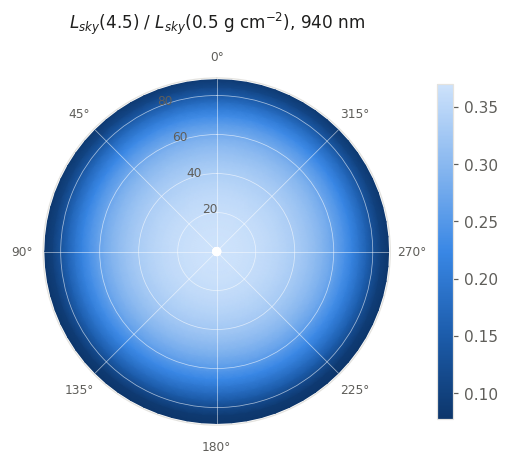

In [14]:
ratio = lut.I_down.sel(wl=0.94, h2o=4.5) / lut.I_down.sel(wl=0.94, h2o=0.5)
fig, ax = plt.subplots(figsize=(4.8, 4.6), subplot_kw=dict(projection="polar"))
th = np.deg2rad(ratio.azi.values)
ax.grid(False)
m = ax.pcolormesh(th, ratio.vza.values, ratio.values, shading="gouraud", cmap=SEQ.reversed())
ax.set_theta_zero_location("N"); ax.set_rlim(0, 89); ax.set_rticks([20, 40, 60, 80])
ax.tick_params(labelsize=8, colors=INK2); ax.grid(color="white", linewidth=0.5, alpha=0.6)
ax.set_title("$L_{sky}$(4.5) / $L_{sky}$(0.5 g cm$^{-2}$), 940 nm", pad=14)
fig.colorbar(m, ax=ax, shrink=0.75, pad=0.1)
plt.tight_layout()

## Using the LUT

The LUT can be interpolated in any dimension, e.g. for a measured water
vapour column and any azimuth:

In [15]:
point = lut.interp(h2o=2.2, vza=VZA, azi=[90., 135., 150.]).sel(wl=0.936)
print((point.I_up / point.I_down).to_series().rename("rho at 936 nm, H2O = 2.2"))

azi
90.0     0.027735
135.0    0.030283
150.0    0.031843
Name: rho at 936 nm, H2O = 2.2, dtype: float64


## Fine vs simplified absorption coupling

`-SOS.AbsModeCKD 2` computes the radiance once, for the absorption optical
thickness equivalent to the CKD transmission at air mass 1; it is much faster
but approximate in strong bands. Any parameter can be a LUT dimension, so
the two modes are compared with a small LUT:

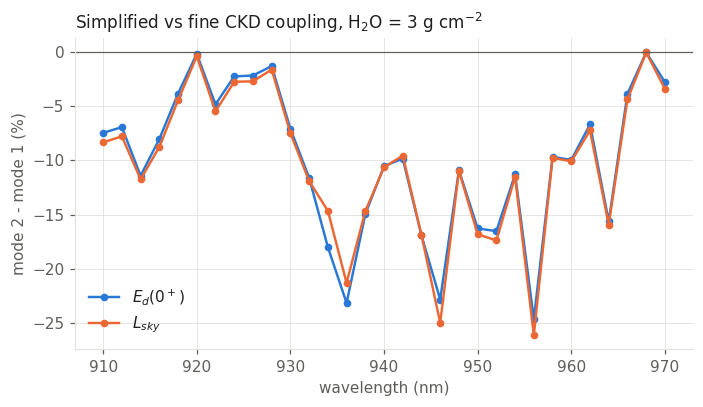

In [16]:
cmp = sosabs.build_lut(grid={"-SOS_Main.Wa": np.round(np.arange(0.910, 0.9701, 0.002), 3),
                             "-SOS.AbsModeCKD": [1, 2]},
                       fixed={**config, "-AP.H2O": 3.0}, verbose=False)
cg = cmp.interp(vza=VZA).sel(azi=AZI)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for c, (name, da) in zip(CAT, [("$E_d(0^+)$", cg.flux_tot_down), ("$L_{sky}$", cg.I_down)]):
    diff = 100 * (da.sel(ckd_mode=2) - da.sel(ckd_mode=1)) / da.sel(ckd_mode=1)
    ax.plot(cg.wl * 1e3, diff, color=c, marker="o", markersize=4, label=name)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("mode 2 - mode 1 (%)")
ax.set_title("Simplified vs fine CKD coupling, H$_2$O = 3 g cm$^{-2}$", loc="left")
ax.legend()
plt.tight_layout()

In the band, the simplified mode underestimates the irradiance and the sky
radiance by up to about 25 %: the CKD-equivalent optical thickness is defined
for an air mass of 1, whereas the slant paths are longer.

## Summary

* `sosabs.build_lut` turns a parameter grid into a self-documented NetCDF
  LUT; the fixed parameters and conventions travel with the data.
* At the 940 nm band centre, going from 0.5 to 4.5 g cm⁻² of water vapour
  reduces $E_d(0^+)$, $L_{sky}$ and $L_t(0^+)$ by about 67-69 %, while the
  ratio $\rho = L_t/L_{sky}$ changes by about 4 % only (see the table above).
* Use `-SOS.AbsModeCKD 1` for quantitative work in strong absorption bands.
* Match the CKD resolution to the spectral sampling: 5 cm⁻¹ for a 0.5 nm step
  around 950 nm (checked with the NetCDF CKD tables of `sosabs.ckd`).

**Reference** – Mobley, C. D. (1999). Estimation of the remote-sensing
reflectance from above-surface measurements. *Applied Optics*, 38(36),
7442–7455. [doi:10.1364/AO.38.007442](https://doi.org/10.1364/AO.38.007442)